In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import load_npz

from src.data_loader import load_raw_data
from src.config import TRAIN_MATRIX_PATH, TEST_MATRIX_PATH, FIGURES_DIR

sns.set_theme(style="whitegrid", palette="muted")

ratings, movies, users = load_raw_data()
train_csr = load_npz(TRAIN_MATRIX_PATH)
test_csr = load_npz(TEST_MATRIX_PATH)

dense_mb = (train_csr.shape[0] * train_csr.shape[1] * 4) / (1024 ** 2)
sparse_mb = (
    train_csr.data.nbytes + train_csr.indices.nbytes + train_csr.indptr.nbytes
) / (1024 ** 2)

print(f"Всього оцінок у датасеті: {len(ratings):,}")
print(f"Розмір щільної (Dense) матриці float32: {dense_mb:.2f} МБ")
print(f"Розмір розрідженої (CSR) матриці:      {sparse_mb:.2f} МБ (економія у {dense_mb / sparse_mb:.1f}x разів)")
ratings.head()

Всього оцінок у датасеті: 1,000,209
Розмір щільної (Dense) матриці float32: 84.49 МБ
Розмір розрідженої (CSR) матриці:      6.11 МБ (економія у 13.8x разів)


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


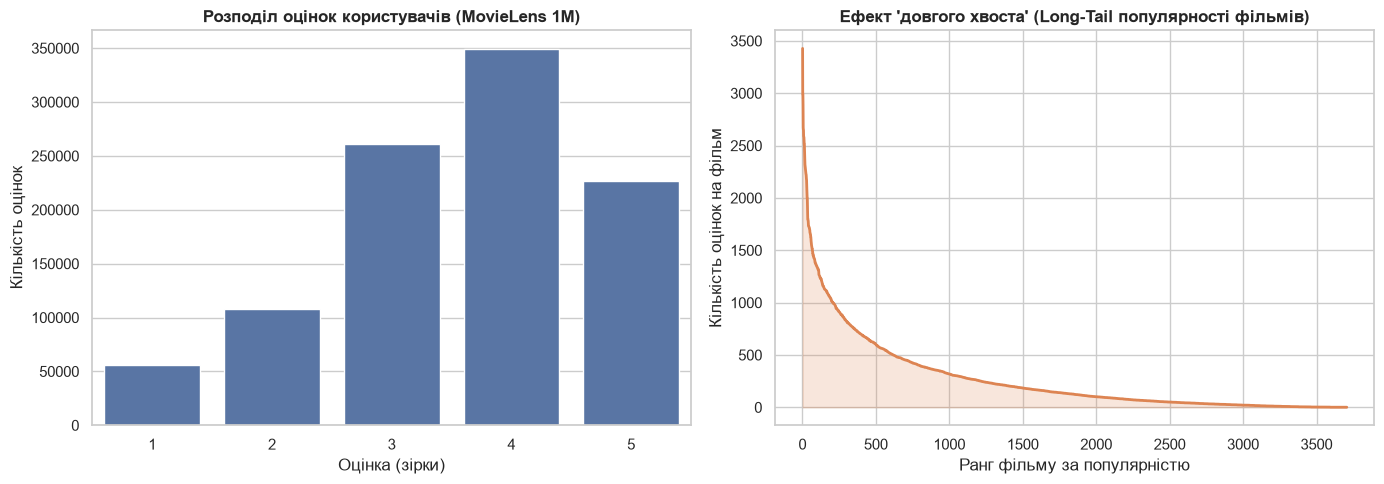

In [2]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Розподіл оцінок (1–5)
rating_counts = ratings["Rating"].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0], color="#4C72B0")
axes[0].set_title("Розподіл оцінок користувачів (MovieLens 1M)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Оцінка (зірки)")
axes[0].set_ylabel("Кількість оцінок")

# 2. Long-tail популярності фільмів
movie_popularity = ratings.groupby("MovieID")["Rating"].count().sort_values(ascending=False).values
axes[1].plot(range(1, len(movie_popularity) + 1), movie_popularity, color="#DD8452", linewidth=2)
axes[1].fill_between(range(1, len(movie_popularity) + 1), movie_popularity, color="#DD8452", alpha=0.2)
axes[1].set_title("Ефект 'довгого хвоста' (Long-Tail популярності фільмів)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ранг фільму за популярністю")
axes[1].set_ylabel("Кількість оцінок на фільм")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_sparsity.png", dpi=150)
plt.show()